In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("hotel_data_modified.csv")

print("shape:", df.shape)
print("columns:", df.columns.tolist())
print(df.dtypes)
df.info()

shape: (119390, 29)
columns: ['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']
hotel                                 str
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                    str
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights             int64
stays_in_week_nights                int64
adults        

In [2]:
df["is_canceled"].mean()

np.float64(0.37041628277075134)

In [3]:
missing = pd.DataFrame({
    "count": df.isna().sum(),
    "ratio": df.isna().mean(),
})
missing.sort_values("ratio", ascending=False)

,count,ratio
company,112593,0.943069
agent,16340,0.136862
country,488,0.004087
children,4,0.000034
is_canceled,0,0.000000
arrival_date_month,0,0.000000
arrival_date_week_number,0,0.000000
stays_in_weekend_nights,0,0.000000
arrival_date_day_of_month,0,0.000000
stays_in_week_nights,0,0.000000


In [4]:
for col in ["agent", "company", "country"]:
    print(col)
    print(df.assign(missing = df[col].isna()).groupby("missing")["is_canceled"].mean())
    print()

agent
missing
False    0.390044
True     0.246634
Name: is_canceled, dtype: float64

company
missing
False    0.175224
True     0.382200
Name: is_canceled, dtype: float64

country
missing
False    0.371373
True     0.137295
Name: is_canceled, dtype: float64



In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,119390.0,NaN,NaN,NaN,0.370416,0.482918,0.0,0.0,0.0,1.0,1.0
lead_time,119390.0,NaN,NaN,NaN,104.011416,106.863097,0.0,18.0,69.0,160.0,737.0
arrival_date_year,119390.0,NaN,NaN,NaN,2016.156554,0.707476,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_month,119390,12,August,13877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,119390.0,NaN,NaN,NaN,27.165173,13.605138,1.0,16.0,28.0,38.0,53.0
arrival_date_day_of_month,119390.0,NaN,NaN,NaN,15.798241,8.780829,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,119390.0,NaN,NaN,NaN,0.927599,0.998613,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,NaN,NaN,NaN,2.500302,1.908286,0.0,1.0,2.0,3.0,50.0
adults,119390.0,NaN,NaN,NaN,1.856403,0.579261,0.0,2.0,2.0,2.0,55.0


In [6]:
df["adults"].value_counts()

adults
2     89680
1     23027
3      6202
0       403
4        62
26        5
27        2
20        2
5         2
40        1
50        1
55        1
6         1
10        1
Name: count, dtype: int64

In [7]:
df.loc[df["adults"] >= 10, ["hotel", "is_canceled", "adults", "arrival_date_year", "arrival_date_month"]]


,hotel,is_canceled,adults,arrival_date_year,arrival_date_month
1539,Resort Hotel,1,40,2015,September
1587,Resort Hotel,1,26,2015,September
1643,Resort Hotel,1,50,2015,September
1752,Resort Hotel,1,26,2015,September
1884,Resort Hotel,1,26,2015,September
1917,Resort Hotel,1,27,2015,September
1962,Resort Hotel,1,27,2015,September
2003,Resort Hotel,1,26,2015,September
2164,Resort Hotel,1,26,2015,October
2173,Resort Hotel,1,55,2015,October


In [8]:
kids_only = (df["adults"] == 0) & ((df["children"] > 0) | (df["babies"] > 0))

print("어른 없이 아이만 있는 예약:", kids_only.sum())

df.loc[kids_only, ["hotel", "is_canceled", "adults", "children", "babies"]]

어른 없이 아이만 있는 예약: 223


,hotel,is_canceled,adults,children,babies
40984,City Hotel,0,0,3.0,0
41048,City Hotel,0,0,2.0,0
41446,City Hotel,0,0,2.0,0
41952,City Hotel,0,0,2.0,0
45158,City Hotel,1,0,2.0,0
...,...,...,...,...,...
117204,City Hotel,0,0,2.0,0
117274,City Hotel,0,0,2.0,0
117303,City Hotel,0,0,2.0,0
117453,City Hotel,0,0,2.0,0


In [9]:
df["total_guests"] = df["adults"] + df["children"].fillna(0) + df["babies"]
df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]

print("인원 0명:", (df["total_guests"] == 0).sum())
print("0박:", (df["total_nights"] == 0).sum())

인원 0명: 180
0박: 715


In [10]:
text_cols = [
    "hotel", "arrival_date_month", "meal", "country",
    "market_segment", "distribution_channel",
    "reserved_room_type", "assigned_room_type",
    "reservation_status", "reservation_status_date",
]
txt = df[text_cols]

print(txt.columns.tolist())

for col in txt.columns:
    print(col, len(txt[col].unique()))

['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'reservation_status', 'reservation_status_date']
hotel 2
arrival_date_month 12
meal 5
country 178
market_segment 8
distribution_channel 5
reserved_room_type 10
assigned_room_type 12
reservation_status 3
reservation_status_date 926


In [11]:
for col in txt.columns:
    s = txt[col].dropna()
    before = len(s.unique())
    after = len(s.str.strip().str.lower().unique())
    print(col, before, after)

hotel 2 2
arrival_date_month 12 12
meal 5 5
country 177 177
market_segment 8 8
distribution_channel 5 5
reserved_room_type 10 10
assigned_room_type 12 12
reservation_status 3 3
reservation_status_date 926 926


In [12]:
for col in ["meal", "market_segment", "distribution_channel"]:
    print(df[col].value_counts())
    print()

meal
BB           92310
HB           14463
SC           10650
Undefined     1169
FB             798
Name: count, dtype: int64

market_segment
Online TA        56477
Offline TA/TO    24219
Groups           19811
Direct           12606
Corporate         5295
Complementary      743
Aviation           237
Undefined            2
Name: count, dtype: int64

distribution_channel
TA/TO        97870
Direct       14645
Corporate     6677
GDS            193
Undefined        5
Name: count, dtype: int64



In [13]:
c = df["country"].dropna()

print("대문자가 아닌 값:", (c != c.str.upper()).sum())
print(df["country"].unique())                                         # 목록을 훑어보고 CN 발견
print(df.loc[df["country"].isin(["CN", "CHN"]), "country"].value_counts())

대문자가 아닌 값: 0
<StringArray>
['PRT', 'GBR', 'USA', 'ESP', 'IRL', 'FRA',   nan, 'ROU', 'NOR', 'OMN',
 ...
 'ATA', 'GTM', 'ASM', 'MRT', 'NCL', 'KIR', 'SDN', 'ATF', 'SLE', 'LAO']
Length: 178, dtype: str
country
CN     1279
CHN     999
Name: count, dtype: int64


In [14]:
hotel_name = ["City Hotel", "Resort Hotel"]
month_name = ["January", "February", "March", "April", "May", "June",
                 "July", "August", "September", "October", "November", "December"]

print(df.loc[df["hotel"].isin(hotel_name) == False, "hotel"].value_counts())
print(df.loc[df["arrival_date_month"].isin(month_name) == False, "arrival_date_month"].value_counts())

Series([], Name: count, dtype: int64)
Series([], Name: count, dtype: int64)


In [15]:
df.groupby(["market_segment", "distribution_channel"])["is_canceled"].agg(["mean", "count"])

mean  count
market_segment distribution_channel                 
Aviation       Corporate             0.224670    227
               TA/TO                 0.100000     10
Complementary  Corporate             0.224719     89
               Direct                0.121528    576
               TA/TO                 0.089744     78
Corporate      Corporate             0.183375   4788
               Direct                0.110465    172
               TA/TO                 0.283582    335
Direct         Corporate             0.111111     90
               Direct                0.155833  12276
               GDS                   0.000000      1
               TA/TO                 0.042194    237
               Undefined             0.500000      2
Groups         Corporate             0.324104   1228
               Direct                0.368886   1472
               TA/TO                 0.651978  17111
Offline TA/TO  Corporate             0.485849    212
               Direct                0.187500     16
               GDS                   0.177778     45
               TA/TO                 0.342312  23946
Online TA      Corporate             0.325581     43
               Direct                0.067669    133
               GDS                   0.197279    147
               TA/TO                 0.368386  56153
               Undefined             1.000000      1
Undefined      Undefined             1.000000      2

In [16]:
print("중복 행:", df.duplicated().sum())
print("전체 취소율:", df["is_canceled"].mean())
print("중복 제거 후 취소율:", df.drop_duplicates()["is_canceled"].mean())

중복 행: 33103
전체 취소율: 0.37041628277075134
중복 제거 후 취소율: 0.27685514619815266


In [17]:
dup_all = df.duplicated(keep = False)

print(df.loc[dup_all, "market_segment"].value_counts(normalize = True))
print()
print(df.loc[dup_all == False, "market_segment"].value_counts(normalize = True))

market_segment
Groups           0.407844
Offline TA/TO    0.301543
Online TA        0.213823
Direct           0.037857
Corporate        0.036566
Complementary    0.001889
Aviation         0.000478
Name: proportion, dtype: float64

market_segment
Online TA        0.612775
Offline TA/TO    0.149662
Direct           0.142095
Corporate        0.048547
Groups           0.035540
Complementary    0.008559
Aviation         0.002797
Undefined        0.000026
Name: proportion, dtype: float64


In [18]:
df.groupby("reservation_status")["is_canceled"].mean()

reservation_status
Canceled     1.0
Check-Out    0.0
No-Show      1.0
Name: is_canceled, dtype: float64

In [19]:
month_map = {
    "January": 1, "February": 2, "March": 3, "April": 4,
    "May": 5, "June": 6, "July": 7, "August": 8,
    "September": 9, "October": 10, "November": 11, "December": 12,
}
df["arrival_month_num"] = df["arrival_date_month"].map(month_map)

df["arrival_date"] = pd.to_datetime(
    pd.DataFrame({
        "year": df["arrival_date_year"],
        "month": df["arrival_month_num"],
        "day": df["arrival_date_day_of_month"],
    }),
    errors="coerce",
)


print("잘못된 날짜:", df["arrival_date"].isna().sum())

df.groupby("arrival_date_year")["arrival_month_num"].agg(["min", "max"])

잘못된 날짜: 0


,min,max
arrival_date_year,,
2015,7,12
2016,1,12
2017,1,8



체크리스트

children 결측은 4건밖에 없으니 0명으로 수정

country 결측 Unknown으로 변경 (결측 예약의 취소율이 달라 정보로 남기기)

agent,company 결측은 여행사나 회사를 거치치않은 예약일테니 0으로 채우기 (결측 여부를 별도 컬럼으로 남기기)

범주형 데이터 meal에서 Undefined는 1169건이나 되니까 SC로 통일시키기

나머지 범주형 데이터 Undefined는 총 7개밖에 안되니까 그냥 삭제!

인원 0명 제거 0박은 당일치기일수 있으니 놔두기

인원수 10명 이상 제거

인원수 다시 계산

reservation_status랑 reservation_status_date는 데이터 누설이니 분석에서 제외

15년과 17년은 12개월이 아니라 연도별로 건수 비교는 안될것 같음

숫자컬럼 min에 음수값 없음 굿

문자컬럼 표기 통일되어있음 굿 (딱 한가지 CN을 CHN으로 바꾸기)

잘못된 날짜는 없음 (날짜 형식이 월을 문자로 써놨는데 숫자로 바꿈)



In [20]:
hotel = df.copy()
before_rows = len(hotel)

hotel["children"] = hotel["children"].fillna(0)

hotel ["country"] = hotel["country"].fillna("Unknown")

hotel["country"] = hotel["country"].replace({"CN": "CHN"})

hotel["has_agent"] = hotel["agent"].notna()
hotel["has_company"] = hotel["company"].notna()
hotel["agent"] = hotel["agent"].fillna(0)
hotel["company"] = hotel["company"].fillna(0)

hotel["meal"] = hotel["meal"].replace({"Undefined": "SC"})

hotel["total_guests"] = hotel["adults"] + hotel["children"] + hotel["babies"]

mask = (
    (hotel["market_segment"] != "Undefined")
    & (hotel["distribution_channel"] != "Undefined")
    & (hotel["total_guests"] > 0)
    & (hotel["adults"] < 10)
    & (hotel["children"] < 10)
    & (hotel["babies"] < 9)
)
hotel = hotel.loc[mask]

qnpfr_cols = ["reservation_status", "reservation_status_date"]
keep_cols = [col for col in hotel.columns if col not in qnpfr_cols]
hotel = hotel[keep_cols]

print("전:", before_rows)
print("후:",len(hotel))

전: 119390
후: 119189


In [21]:
print(hotel["meal"].value_counts())

meal
BB    92219
HB    14454
SC    11718
FB      798
Name: count, dtype: int64


In [22]:
assert hotel.isna().sum().sum() == 0
assert hotel["is_canceled"].isin([0, 1]).all()
assert (hotel["total_guests"] > 0).all()
assert (hotel["meal"] != "Undefined").all()
assert (hotel["market_segment"] != "Undefined").all()
assert (hotel["distribution_channel"] != "Undefined").all()
assert (hotel["country"] != "CN").all()
assert hotel["arrival_month_num"].between(1, 12).all()

print(df.shape)
print("수정 전 취소율:", df["is_canceled"].mean())
print(hotel.shape)
print("수정 후 취소율:", hotel["is_canceled"].mean())

(119390, 33)
수정 전 취소율: 0.37041628277075134
(119189, 33)
수정 후 취소율: 0.3706801802179731



데이터도 정리했으니 이제 transform 해야하는데 흠.......................................
데이터에서 예약 취소와 관련 있는 요소들을 쭉 적어보기

예약한 시기 : lead_time

도착한 시기 : arrival_date_month, arrival_date_year, arrival_date_day_of_month

머문 기간 : stays_in_weekend_nights, stays_in_week_nights

예약자 정보 : is_repeated_guest, previous_cancellations, country, adults children babies, reserved_room_type

예약 경로 : market_segment, previous_cancellations, country

고객 요청사항 : total_of_special_requests, meal, required_car_parking_spaces


일단 lead_time은 너무 다양하니 구간을 나누고

도착날짜는 틀린 날짜 있는지 계산할때 연월일 합쳐서 arrival_date로 만든거 똑같이 넣고 추가로 도착요일 만들면 좋을듯

주중 주말로 나뉘어져 있는것도 합쳐서 총 숙박일수로 확인하면 좋을듯

아이가 있는지 없는지도 분류하면 좋을듯

주차공간이 없어서 예약취소했을수도 있고

호텔이 포르투갈에 있으니 포르투갈 사람인지도 확인하고

어느 나라에서 많이 오고 많이 취소하는지도

대기가 걸려서 취소했을수도 있으니 대기했는지 안했는지

요청사항이 있었는지도 간단하게 True or False로만

성수기 비성수기도 분류하기


In [23]:
tf = hotel.copy()
before_rows = len(tf)

month_map = {
    "January": 1, "February": 2, "March": 3, "April": 4,
    "May": 5, "June": 6, "July": 7, "August": 8,
    "September": 9, "October": 10, "November": 11, "December": 12,
}
tf["arrival_month_num"] = tf["arrival_date_month"].map(month_map)

tf["arrival_date"] = pd.to_datetime(
    pd.DataFrame({
        "year": tf["arrival_date_year"],
        "month": tf["arrival_month_num"],
        "day": tf["arrival_date_day_of_month"],
    }),
    errors="coerce",
)

tf["arrival_dayofweek"] = tf["arrival_date"].dt.dayofweek

tf["total_nights"] = tf["stays_in_weekend_nights"] + tf["stays_in_week_nights"]

tf["lead_time_group"] = pd.cut(
    tf["lead_time"],
    bins = [0, 7, 30, 90, 180, 365, 1000],
    labels = ["0-6 days", "7-29 days", "30-89 days", "90-179 days", "180-364 days", "365 days+"],
    right = False,
)

tf["nights_group"] = pd.cut(
    tf["total_nights"],
    bins = [0, 1, 3, 7, 14, 1000],
    labels = ["0 nights", "1-2 nights", "3-6 nights", "7-13 nights", "14 nights+"],
    right = False,
)

tf["has_kids"] = ((tf["children"] + tf["babies"]) > 0)
tf["has_prev_cancel"] = (tf["previous_cancellations"] > 0)
tf["has_special_request"] = (tf["total_of_special_requests"] > 0)
tf["has_waiting"] = (tf["days_in_waiting_list"] > 0)
tf["is_local"] = (tf["country"] == "PRT")

season_map = {6: "peak", 7: "peak", 8: "peak",
              11: "off_peak", 12: "off_peak", 1: "off_peak", 2: "off_peak"}
tf["season"] = tf["arrival_month_num"].map(season_map).fillna("normal")

tf["country_count"] = tf.groupby("country")["country"].transform("size")
tf["country_group"] = np.where(tf["country_count"] >= 1000, tf["country"], "Other")

In [24]:
assert len(tf) == before_rows

new_cols = [
    "arrival_date", "arrival_dayofweek", "lead_time_group", "nights_group", "has_kids", "has_prev_cancel", "total_nights",
    "has_special_request", "has_waiting", "country_count", "country_group", "is_local", "season"
]

for col in new_cols:
    print(col, tf[col].isna().sum())
    assert tf[col].isna().sum() == 0

assert tf["season"].isin(["peak", "off_peak", "normal"]).all()

print("validation passed")
print(tf.shape)

arrival_date 0
arrival_dayofweek 0
lead_time_group 0
nights_group 0
has_kids 0
has_prev_cancel 0
total_nights 0
has_special_request 0
has_waiting 0
country_count 0
country_group 0
is_local 0
season 0
validation passed
(119189, 44)


In [25]:
tf[["lead_time", "lead_time_group", "total_nights", "nights_group",
    "country", "country_group", "arrival_date", "arrival_dayofweek"]].head()

,lead_time,lead_time_group,total_nights,nights_group,country,country_group,arrival_date,arrival_dayofweek
0,342,180-364 days,0,0 nights,PRT,PRT,2015-07-01,2
1,737,365 days+,0,0 nights,PRT,PRT,2015-07-01,2
2,7,7-29 days,1,1-2 nights,GBR,GBR,2015-07-01,2
3,13,7-29 days,1,1-2 nights,GBR,GBR,2015-07-01,2
4,14,7-29 days,2,1-2 nights,GBR,GBR,2015-07-01,2


In [26]:
print(tf["lead_time_group"].value_counts())
print()
print(tf["nights_group"].value_counts())
print()
print(tf["country_group"].value_counts())

lead_time_group
30-89 days      29892
90-179 days     26442
180-364 days    21726
7-29 days       19614
0-6 days        18303
365 days+        3212
Name: count, dtype: int64

nights_group
3-6 nights     56048
1-2 nights     48632
7-13 nights    12523
14 nights+      1341
0 nights         645
Name: count, dtype: int64

country_group
PRT      48463
GBR      12119
FRA      10401
Other    10179
ESP       8560
DEU       7285
ITA       3761
IRL       3374
BEL       2342
CHN       2278
BRA       2222
NLD       2103
USA       2093
CHE       1726
AUT       1263
SWE       1020
Name: count, dtype: int64


                 cancel_rate  bookings
lead_time_group                       
0-6 days               0.093     18303
7-29 days              0.266     19614
30-89 days             0.378     29892
90-179 days            0.446     26442
180-364 days           0.552     21726
365 days+              0.680      3212


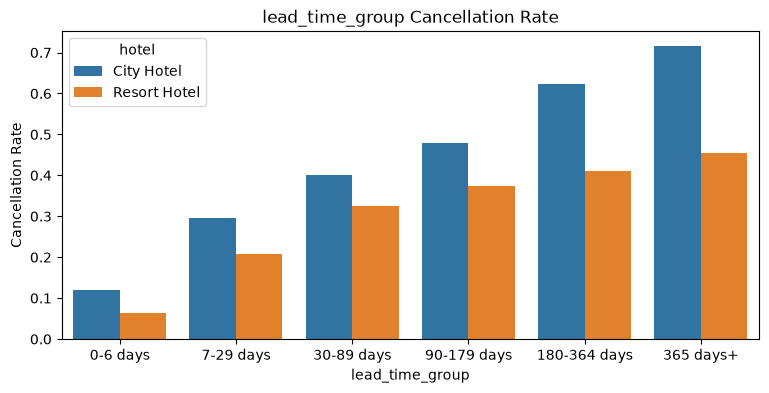

In [27]:
table = tf.groupby("lead_time_group").agg(
    cancel_rate=("is_canceled", "mean"),
    bookings=("is_canceled", "size"),
).round(3)
print(table)

summary = tf.groupby(["hotel", "lead_time_group"]).agg(cancel_rate=("is_canceled", "mean")).reset_index()
plt.figure(figsize=(9, 4))
sns.barplot(data=summary, x="lead_time_group", y="cancel_rate", hue="hotel")
plt.title("lead_time_group Cancellation Rate")
plt.ylabel("Cancellation Rate")
plt.show()

                   cancel_rate  bookings
arrival_month_num                       
1                        0.305      5920
2                        0.334      8052
3                        0.322      9768
4                        0.408     11078
5                        0.397     11780
6                        0.415     10929
7                        0.375     12642
8                        0.378     13857
9                        0.391     10492
10                       0.381     11141
11                       0.313      6771
12                       0.350      6759


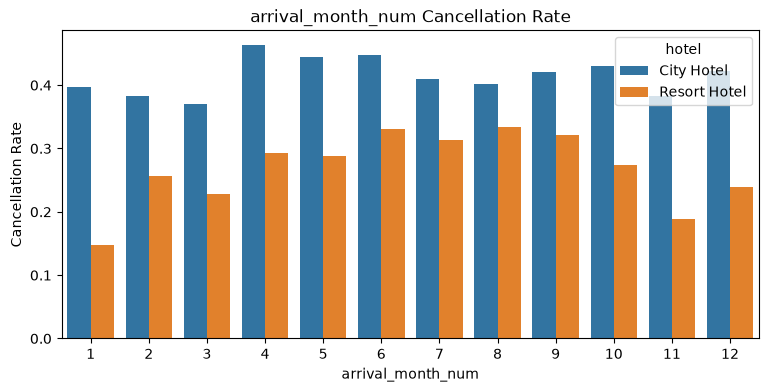

In [28]:
table = tf.groupby("arrival_month_num").agg(
    cancel_rate=("is_canceled", "mean"),
    bookings=("is_canceled", "size"),
).round(3)
print(table)

summary = tf.groupby(["hotel", "arrival_month_num"]).agg(cancel_rate=("is_canceled", "mean")).reset_index()
plt.figure(figsize=(9, 4))
sns.barplot(data=summary, x="arrival_month_num", y="cancel_rate", hue="hotel")
plt.title("arrival_month_num Cancellation Rate")
plt.ylabel("Cancellation Rate")
plt.show()

                   cancel_rate  bookings
arrival_dayofweek                       
0                        0.341     18147
1                        0.329     13969
2                        0.362     16097
3                        0.412     19222
4                        0.407     19602
5                        0.395     18031
6                        0.323     14121


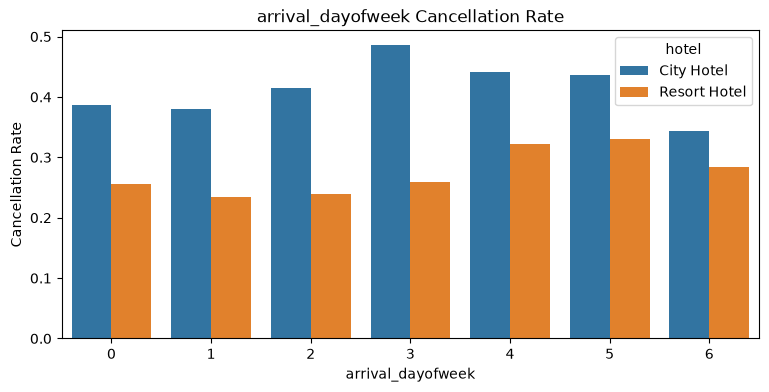

In [29]:
table = tf.groupby("arrival_dayofweek").agg(
    cancel_rate=("is_canceled", "mean"),
    bookings=("is_canceled", "size"),
).round(3)
print(table)

summary = tf.groupby(["hotel", "arrival_dayofweek"]).agg(cancel_rate=("is_canceled", "mean")).reset_index()
plt.figure(figsize=(9, 4))
sns.barplot(data=summary, x="arrival_dayofweek", y="cancel_rate", hue="hotel")
plt.title("arrival_dayofweek Cancellation Rate")
plt.ylabel("Cancellation Rate")
plt.show()

          cancel_rate  bookings
season                         
normal          0.381     54259
off_peak        0.327     27502
peak            0.387     37428


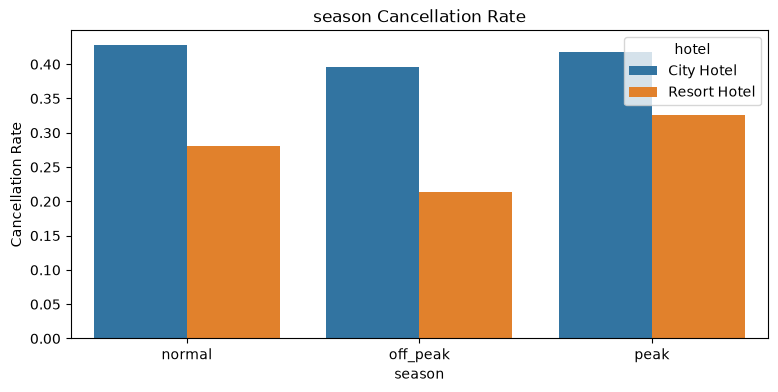

In [30]:
table = tf.groupby("season").agg(
    cancel_rate=("is_canceled", "mean"),
    bookings=("is_canceled", "size"),
).round(3)
print(table)

summary = tf.groupby(["hotel", "season"]).agg(cancel_rate=("is_canceled", "mean")).reset_index()
plt.figure(figsize=(9, 4))
sns.barplot(data=summary, x="season", y="cancel_rate", hue="hotel")
plt.title("season Cancellation Rate")
plt.ylabel("Cancellation Rate")
plt.show()

              cancel_rate  bookings
nights_group                       
0 nights            0.036       645
1-2 nights          0.358     48632
3-6 nights          0.391     56048
7-13 nights         0.346     12523
14 nights+          0.371      1341


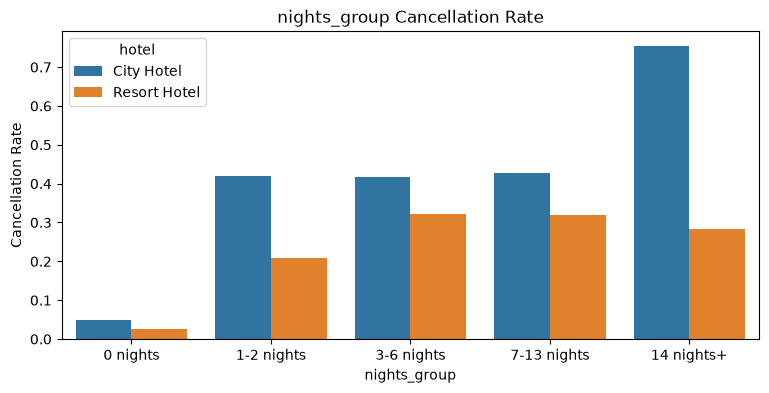

In [31]:
table = tf.groupby("nights_group").agg(
    cancel_rate=("is_canceled", "mean"),
    bookings=("is_canceled", "size"),
).round(3)
print(table)

summary = tf.groupby(["hotel", "nights_group"]).agg(cancel_rate=("is_canceled", "mean")).reset_index()
plt.figure(figsize=(9, 4))
sns.barplot(data=summary, x="nights_group", y="cancel_rate", hue="hotel")
plt.title("nights_group Cancellation Rate")
plt.ylabel("Cancellation Rate")
plt.show()

In [32]:
for col in ["is_repeated_guest", "has_prev_cancel", "has_kids", "is_local"]:
    table = tf.groupby(col).agg(
        cancel_rate=("is_canceled", "mean"),
        bookings=("is_canceled", "size"),
    ).round(3)
    print(table)
    print()

                   cancel_rate  bookings
is_repeated_guest                       
0                        0.378    115434
1                        0.146      3755

                 cancel_rate  bookings
has_prev_cancel                       
False                  0.339    112710
True                   0.917      6479

          cancel_rate  bookings
has_kids                       
False           0.372    109861
True            0.349      9328

          cancel_rate  bookings
is_local                       
False           0.236     70726
True            0.567     48463



In [33]:
tf.groupby("country_group").agg(
    cancel_rate=("is_canceled", "mean"),
    bookings=("is_canceled", "size"),
).round(3).sort_values("cancel_rate", ascending=False)

,cancel_rate,bookings
country_group,,
PRT,0.567,48463
BRA,0.374,2222
ITA,0.354,3761
CHN,0.314,2278
Other,0.290,10179
ESP,0.254,8560
CHE,0.248,1726
IRL,0.247,3374
USA,0.239,2093


                cancel_rate  bookings
market_segment                       
Groups                0.611     19791
Online TA             0.368     56406
Offline TA/TO         0.343     24176
Aviation              0.221       235
Corporate             0.188      5281
Direct                0.153     12572
Complementary         0.122       728


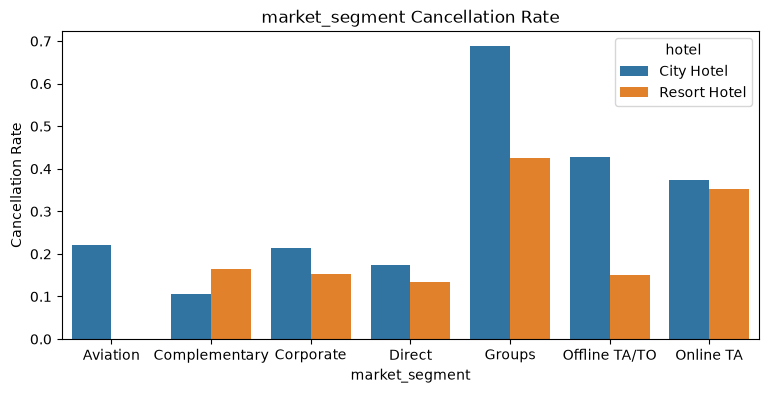

In [34]:
table = tf.groupby("market_segment").agg(
    cancel_rate=("is_canceled", "mean"),
    bookings=("is_canceled", "size"),
).round(3)
print(table.sort_values("cancel_rate", ascending=False))

summary = tf.groupby(["hotel", "market_segment"]).agg(cancel_rate=("is_canceled", "mean")).reset_index()
plt.figure(figsize=(9, 4))
sns.barplot(data=summary, x="market_segment", y="cancel_rate", hue="hotel")
plt.title("market_segment Cancellation Rate")
plt.ylabel("Cancellation Rate")
plt.show()

In [35]:
for col in ["distribution_channel", "has_agent", "has_company"]:
    table = tf.groupby(col).agg(
        cancel_rate=("is_canceled", "mean"),
        bookings=("is_canceled", "size"),
    ).round(3)
    print(table)
    print()

                      cancel_rate  bookings
distribution_channel                       
Corporate                   0.221      6650
Direct                      0.174     14603
GDS                         0.192       193
TA/TO                       0.411     97743

           cancel_rate  bookings
has_agent                       
False            0.246     16269
True             0.390    102920

             cancel_rate  bookings
has_company                       
False              0.382    112421
True               0.174      6768



                           cancel_rate  bookings
total_of_special_requests                       
0                                0.478     70187
1                                0.220     33178
2                                0.221     12950
3                                0.178      2494
4                                0.106       340
5                                0.050        40


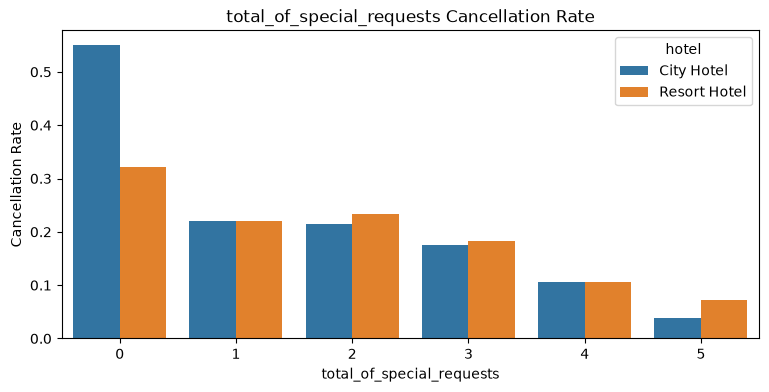

In [36]:
table = tf.groupby("total_of_special_requests").agg(
    cancel_rate=("is_canceled", "mean"),
    bookings=("is_canceled", "size"),
).round(3)
print(table)

summary = tf.groupby(["hotel", "total_of_special_requests"]).agg(cancel_rate=("is_canceled", "mean")).reset_index()
plt.figure(figsize=(9, 4))
sns.barplot(data=summary, x="total_of_special_requests", y="cancel_rate", hue="hotel")
plt.title("total_of_special_requests Cancellation Rate")
plt.ylabel("Cancellation Rate")
plt.show()

In [37]:
tf.groupby("required_car_parking_spaces").agg(
    cancel_rate=("is_canceled", "mean"),
    bookings=("is_canceled", "size"),
).round(3)

,cancel_rate,bookings
required_car_parking_spaces,,
0,0.395,111781
1,0.000,7375
2,0.000,28
3,0.000,3
8,0.000,2


In [38]:
pd.pivot_table(tf, index="market_segment", columns="is_local",
               values="is_canceled", aggfunc="mean").round(3)

is_local,False,True
market_segment,,
Aviation,0.083,0.398
Complementary,0.014,0.134
Corporate,0.028,0.234
Direct,0.108,0.206
Groups,0.072,0.841
Offline TA/TO,0.015,0.678
Online TA,0.344,0.454


In [39]:
pd.pivot_table(tf, index="lead_time_group", columns="has_special_request",
               values="is_canceled", aggfunc="mean").round(3)

has_special_request,False,True
lead_time_group,,
0-6 days,0.118,0.057
7-29 days,0.336,0.193
30-89 days,0.486,0.244
90-179 days,0.576,0.259
180-364 days,0.668,0.319
365 days+,0.847,0.038


In [40]:
pd.pivot_table(tf, index="lead_time_group", columns="market_segment",
               values="is_canceled", aggfunc="mean").round(3)

market_segment,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA
lead_time_group,,,,,,,
0-6 days,0.213,0.097,0.087,0.079,0.187,0.118,0.089
7-29 days,0.250,0.152,0.163,0.183,0.325,0.183,0.310
30-89 days,NaN,0.212,0.386,0.212,0.520,0.298,0.397
90-179 days,NaN,0.222,0.572,0.193,0.637,0.383,0.443
180-364 days,NaN,0.000,0.489,0.253,0.687,0.466,0.534
365 days+,NaN,0.000,NaN,0.667,0.802,0.416,0.833


In [41]:
counts = (
    tf.groupby(["lead_time_group", "market_segment"])
    .agg(bookings=("is_canceled", "size"))
    .reset_index()
)

pd.pivot_table(
    counts,
    index="lead_time_group",
    columns="market_segment",
    values="bookings",
    aggfunc="sum",
)

market_segment,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA
lead_time_group,,,,,,,
0-6 days,183.0,476.0,2547.0,5066.0,530.0,1864.0,7637.0
7-29 days,52.0,164.0,1523.0,2401.0,1641.0,2653.0,11180.0
30-89 days,NaN,66.0,900.0,2415.0,3997.0,5864.0,16650.0
90-179 days,NaN,18.0,264.0,1827.0,4550.0,6462.0,13321.0
180-364 days,NaN,3.0,47.0,857.0,6902.0,6317.0,7600.0
365 days+,NaN,1.0,NaN,6.0,2171.0,1016.0,18.0


In [42]:
main_segments = ["Groups", "Online TA", "Offline TA/TO", "Direct"]

tf_main = tf.loc[tf["market_segment"].isin(main_segments)]

pd.pivot_table(
    tf_main,
    index="lead_time_group",
    columns="market_segment",
    values="is_canceled",
    aggfunc="mean",
).round(3)

market_segment,Direct,Groups,Offline TA/TO,Online TA
lead_time_group,,,,
0-6 days,0.079,0.187,0.118,0.089
7-29 days,0.183,0.325,0.183,0.310
30-89 days,0.212,0.520,0.298,0.397
90-179 days,0.193,0.637,0.383,0.443
180-364 days,0.253,0.687,0.466,0.534
365 days+,0.667,0.802,0.416,0.833


In [43]:
check_cols = [
    "is_canceled", "lead_time", "is_local", "has_prev_cancel",
    "has_special_request", "is_repeated_guest", "has_company", "has_waiting",
]
tf[check_cols].corr()["is_canceled"].sort_values()

has_special_request   -0.264927
has_company           -0.099662
is_repeated_guest     -0.083725
has_waiting            0.099257
has_prev_cancel        0.271101
lead_time              0.292723
is_local               0.336804
is_canceled            1.000000
Name: is_canceled, dtype: float64

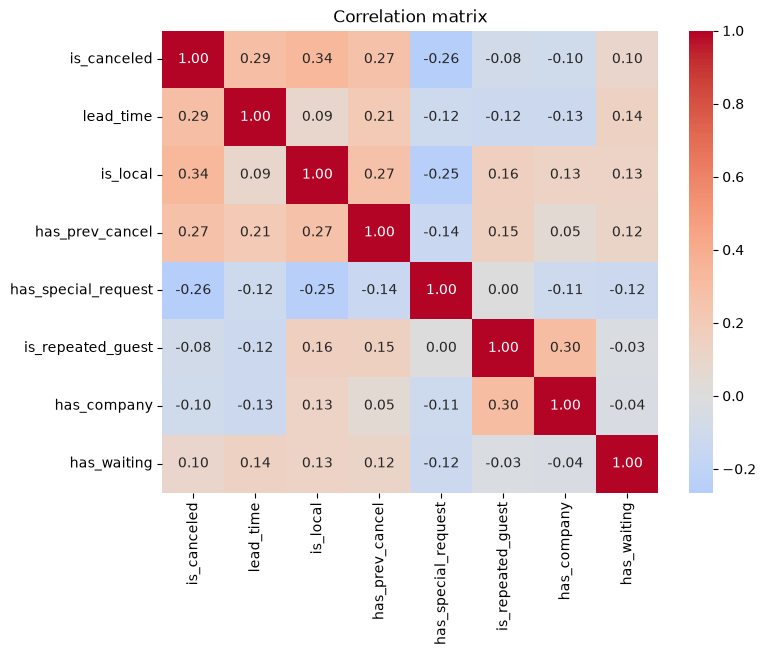

In [44]:
corr = tf[check_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.show()

In [45]:
seg = tf.groupby("market_segment").agg(
    bookings=("is_canceled", "size"),
    cancels=("is_canceled", "sum"),
    cancel_rate=("is_canceled", "mean"),
)

seg["booking_share"] = (seg["bookings"] / seg["bookings"].sum() * 100).round(1)
seg["cancel_share"] = (seg["cancels"] / seg["cancels"].sum() * 100).round(1)
seg["cancel_rate"] = seg["cancel_rate"].round(3)

seg.sort_values("cancel_share", ascending=False)

,bookings,cancels,cancel_rate,booking_share,cancel_share
market_segment,,,,,
Online TA,56406,20734,0.368,47.3,46.9
Groups,19791,12094,0.611,16.6,27.4
Offline TA/TO,24176,8296,0.343,20.3,18.8
Direct,12572,1925,0.153,10.5,4.4
Corporate,5281,991,0.188,4.4,2.2
Complementary,728,89,0.122,0.6,0.2
Aviation,235,52,0.221,0.2,0.1


In [46]:
tf["prt_group_offline"] = (
    (tf["country"] == "PRT")
    & (tf["market_segment"].isin(["Groups", "Offline TA/TO"]))
).astype(int)

prt = tf.groupby("prt_group_offline").agg(
    bookings=("is_canceled", "size"),
    cancels=("is_canceled", "sum"),
    cancel_rate=("is_canceled", "mean"),
)
prt["booking_share"] = (prt["bookings"] / prt["bookings"].sum() * 100).round(1)
prt["cancel_share"] = (prt["cancels"] / prt["cancels"].sum() * 100).round(1)
prt["cancel_rate"] = prt["cancel_rate"].round(3)

prt

,bookings,cancels,cancel_rate,booking_share,cancel_share
prt_group_offline,,,,,
0,93351,24402,0.261,78.3,55.2
1,25838,19779,0.766,21.7,44.8


In [47]:
tf["long_lead"] = (tf["lead_time"] >= 90).astype(int)

prt = tf.groupby("long_lead").agg(
    bookings=("is_canceled", "size"),
    cancels=("is_canceled", "sum"),
    cancel_rate=("is_canceled", "mean"),
)
prt["booking_share"] = (prt["bookings"] / prt["bookings"].sum() * 100).round(1)
prt["cancel_share"] = (prt["cancels"] / prt["cancels"].sum() * 100).round(1)
prt["cancel_rate"] = prt["cancel_rate"].round(3)

prt

,bookings,cancels,cancel_rate,booking_share,cancel_share
long_lead,,,,,
0,67809,18225,0.269,56.9,41.3
1,51380,25956,0.505,43.1,58.7


In [48]:
prt = tf.groupby("has_special_request").agg(
    bookings=("is_canceled", "size"),
    cancels=("is_canceled", "sum"),
    cancel_rate=("is_canceled", "mean"),
)
prt["booking_share"] = (prt["bookings"] / prt["bookings"].sum() * 100).round(1)
prt["cancel_share"] = (prt["cancels"] / prt["cancels"].sum() * 100).round(1)
prt["cancel_rate"] = prt["cancel_rate"].round(3)

prt

,bookings,cancels,cancel_rate,booking_share,cancel_share
has_special_request,,,,,
False,70187,33521,0.478,58.9,75.9
True,49002,10660,0.218,41.1,24.1


In [49]:
prt = tf.groupby("has_prev_cancel").agg(
    bookings=("is_canceled", "size"),
    cancels=("is_canceled", "sum"),
    cancel_rate=("is_canceled", "mean"),
)
prt["booking_share"] = (prt["bookings"] / prt["bookings"].sum() * 100).round(1)
prt["cancel_share"] = (prt["cancels"] / prt["cancels"].sum() * 100).round(1)
prt["cancel_rate"] = prt["cancel_rate"].round(3)

prt

,bookings,cancels,cancel_rate,booking_share,cancel_share
has_prev_cancel,,,,,
False,112710,38241,0.339,94.6,86.6
True,6479,5940,0.917,5.4,13.4


In [50]:
prt = tf.groupby("hotel").agg(
    bookings=("is_canceled", "size"),
    cancels=("is_canceled", "sum"),
    cancel_rate=("is_canceled", "mean"),
)
prt["booking_share"] = (prt["bookings"] / prt["bookings"].sum() * 100).round(1)
prt["cancel_share"] = (prt["cancels"] / prt["cancels"].sum() * 100).round(1)
prt["cancel_rate"] = prt["cancel_rate"].round(3)

prt

,bookings,cancels,cancel_rate,booking_share,cancel_share
hotel,,,,,
City Hotel,79157,33075,0.418,66.4,74.9
Resort Hotel,40032,11106,0.277,33.6,25.1



### [오래 전 예약할수록 취소가 많다] - 1주일 이내 예약 9.3% vs 1년 이상 전 예약 68%

근거 : 예약 경로와 특별 요청 여부를 나눠 봐도 모든 그룹에서 같은 방향인 독립적인 요인

도착일까지 시간이 길수록 일정이 바뀔 가능성이 높아서 그런거 같음. 일단 잡아두고 아님 말고 하는듯 함.

### [포르투갈(현지인) 고객의 취소율이 높다] - 포르투갈 고객 56.7% vs 외국 고객 23.6%

근거 : 교차 검증때 같은 단체 예약이라도 포르투갈 고객 84.1% vs 외국 고객 7.2%였음.(오프라인 여행사도 비슷함)

과거 취소 이력이 있는 예약의 52%가 단체이고, 취소 이력이 있는 단체는 취소율 100%인걸로 봐서 국내 여행사와

단체가 반복해서 방을 잡고 취소한 것 때문에 개인이 아닌 단체가 문제인걸로 보여짐.

### [여행사와 단체 예약은 취소가 많고, 회사 또는 직접 예약하면 취소가 적다] - 단체 61.1%, 온라인 여행사 36.8% vs 직접 15.3%, 기업 18.8%

근거 : 여행사 경유(has_agent) 39% vs 미경유 24.6% / 회사 경유(has_company) 17.4% vs 미경유 38.2% 라는 결과 때문

직접 예약은 본인이 골라서 예약하고, 회사 예약은 업무 일정이 확정된 후 잡기 때문인 것 같음.

### [특별 요청을 한 고객은 취소가 절반] - 요청 없음 47.8% vs 요청 있음 21.8% (요청이 많을수록 더 낮음)

근거 : lead_time 구간별로 나눠봐도 모든 구간에서 요청 있는 예약이 절반 수준

실제로 투숙하기 위해서 원하는걸 요청하는것 때문인지 그만큼 취소율이 줄어듬.

### [과거에 취소한 고객은 또 취소한다] - 취소 이력 있음 91.7% vs 없음 33.9%

근거 : 이력 보유 예약의 절반 이상이 단체 예약(포르투갈 고객 취소율이 높은것과 연결됨.)

그냥 예약하고 취소하는게 성격이거나 여행사가 대량 예약하고 사람 없으면 취소해버리는것 같음.

데이터에 고객 ID가 없어서 같은 고객인지는 모름

### [호텔별로 차이가 난다]

city hotel에서 전체 취소 중 4분의 3이 발생한다.

단체 또는 오프라인 여행사 취소율이 특히 높다(68.9%, 42.9%) 14박 이상 장기 예약도 높다 (75.5%)

resort hotel은 직접 예약 비중이 높음. 성수기에 취소율이 가장 높음.


# 예약 취소율 개선 방안

#### 1. 국내 단체 또는 여행사 예약 관리 (원인 : 포르투갈 단체 여행사 예약 (취소율 76.6%))
  - 단체 예약 시 일정 비율 이상 취소하면 위약금을 부과하기
  - 여행사별 취소율을 계산해서 취소가 많으면 배정 객실 수 제한을 주고, 반대로 적을수록 vip 대우 해주기
  - 도착 며칠 전까지 확정되지 않은 방은 자동으로 반환하게 해서 반환된 방은 다시 팔기

#### 2. 오래전에 한 예약 관리 (원인 : lead_time 90일 이상 예약(취소율 50.5%))
  - 도착 30일, 7일 전에 예약 확인 메세지를 보내면 일찍 취소하게 되어서 다시 판매할 시간이 생김
  - 예약할때 보증금을 추가하기 

#### 3. 특별 요청 유도하기 (원인 : 특별 요청이 없는 예약 (취소율 47.8%))
  - 예약 직후, 선호하는 층이나 기념일 또는 조식 등을 미리 안내해서 요청 받아내기

#### 4. 직접 예약과 재방문 고객 늘리기 (원인 : 온라인 여행사 예약 (취소율 36.8%))
  - 직접 예약할 시 조식 할인 등을 제공하기
  - 도장 쿠폰 만들어서 10번 오면 1번 꽁짜 (10번이 적으면 20번으로)

#### 5. 취소 위험이 높은 예약 미리 알아내기
  - 그동안 찾은 요인들로 위험등급을 매기기. (과거 취소 이력이 있는 예약은 취소율 91.7%이니 매우 위험한 1등급 최고 위험군.)
  - 예상 취소만큼 고객을 조금 더 받아 빈방을 줄이기 (정확한 예측이 가능할때만 하도록 주의...)

#### 6. 호텔별로 적용 우선순위
  - city hotel : 취소의 75%가 city고, 그 중 단체 또는 여행사 취소율이 68.7% 특히 높게 나옴. 그러므로 1번을 먼저 하기
  - resort hotel : 성수기에 취소율이 많이 나오므로 예약 확인 메세지 보내기를 1순위로 하기 (직접 예약이 많은 편이라 직접 소통 가능)